# Lab 2

### Setup
Load the libraries and dataset.

In [30]:
%pip install numpy matplotlib scipy scikit-learn pandas jupyterlab ipywidgets seaborn kagglehub --quiet

Note: you may need to restart the kernel to use updated packages.


In [31]:
import kagglehub
import os
import pandas as pd


# Download latest version
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")
df = pd.read_csv(os.path.join(path, "winequality-red.csv"))
print(df.info())

# Impute NaN values with column mean
df.fillna(df.mean(), inplace=True)
 
target_col = 'quality'
X = df.drop(columns=[target_col])
y = df[target_col]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None


### Split the dataset & preprocess
Split the dataset into training, testing and validation sets.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Split the dataset into training (70%), validation (15%), and testing (15%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Normalize features (analogous to calculating z-scores without magnitude)
# Calculates mean, std on training set, applies to all sets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

### Decision Tree Building

In [33]:
# Import classifier because quality is int (discrete)
from sklearn.tree import DecisionTreeClassifier
import numpy as np


def build_decision_tree(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    max_depth: int | None = None,
):
    clf = DecisionTreeClassifier(
        max_depth=max_depth,
        random_state=42,
        # Disable pruning to see overfitting
        ccp_alpha=0,
    )
    clf.fit(X_train, y_train)
    return clf, clf.score(X_test, y_test), clf.score(X_val, y_val)

### Predicting target feature and analyzing noise impact on training

Plotting decision trees...
Best Depth: 5
Most Overfit Depth: None


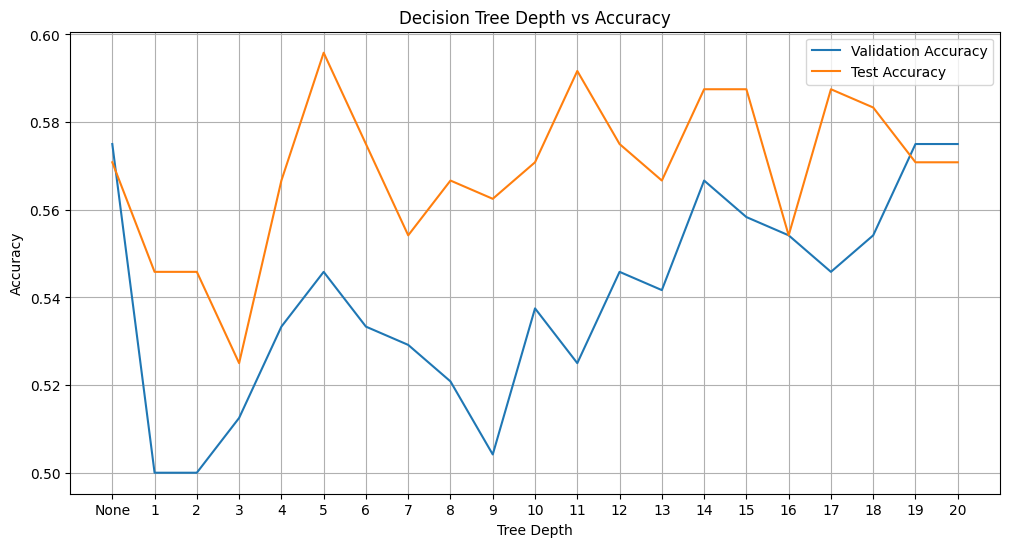



Plotting decision trees with noise...
Best Depth: 4
Most Overfit Depth: 12


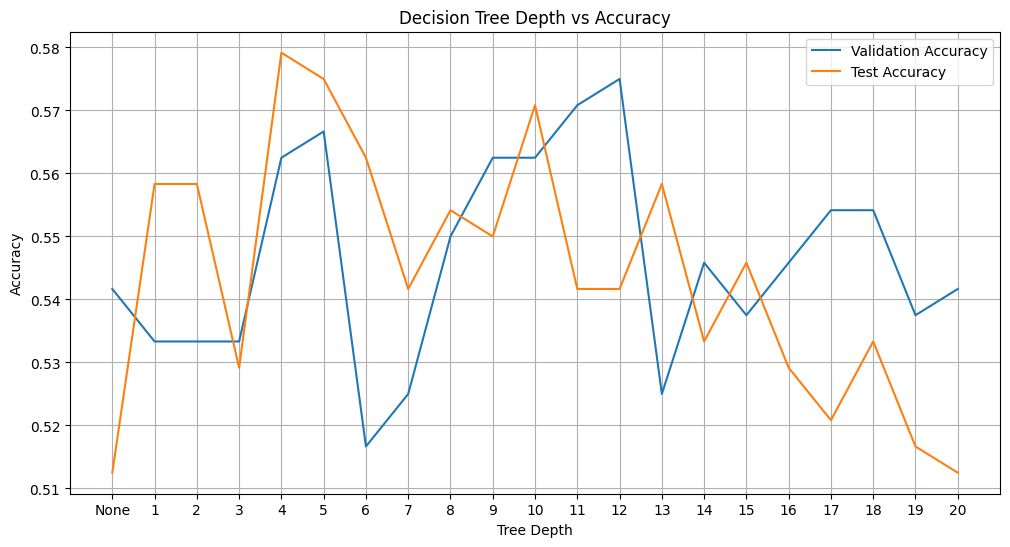



In [34]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import plot_tree

depth, val_acc, test_acc = "Depth", "Validation Accuracy", "Test Accuracy"


def plot_trees(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
):
    depths = np.concatenate(([None], np.arange(1, 21)))  # type: ignore
    models = np.array(
        [
            build_decision_tree(
                X_train, y_train, X_val, y_val, X_test, y_test, max_depth=mode
            )
            for mode in depths
        ]
    )

    # Visualize the results
    results = pd.DataFrame(
        {
            depth: depths.astype(str),  # better for categorical x-axis
            val_acc: np.array([val for _, _, val in models]),
            test_acc: np.array([test for _, test, _ in models]),
        }
    )

    # Print top depth
    best_tree_idx = results[test_acc].idxmax()
    best_depth = results.loc[best_tree_idx]
    print(f"Best Depth: {best_depth[depth]}")

    # Print most overfitted depth
    results["overfit"] = results[val_acc] - results[test_acc]
    most_overfit_idx = results["overfit"].idxmax()
    most_overfit_depth = results.loc[most_overfit_idx]
    print(f"Most Overfit Depth: {most_overfit_depth[depth]}")

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=results, x=depth, y=val_acc, label=val_acc)
    sns.lineplot(data=results, x=depth, y=test_acc, label=test_acc)
    plt.title("Decision Tree Depth vs Accuracy")
    plt.xlabel("Tree Depth")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

    # Visualize the best tree
    best_model = models[best_tree_idx][0]
    plt.figure(figsize=(160, 24))
    plot_tree(best_model, filled=True, feature_names=X.columns.to_list(), fontsize=16)
    plt.title("Best Decision Tree")
    plt.show()


print("Plotting decision trees...")
plot_trees(X_train, y_train, X_val, y_val, X_test, y_test)

# Adding some noise to see if it helps with overfitting
generator = np.random.default_rng(42)
X_train_noisy = X_train + generator.uniform(-0.1, 0.1, X_train.shape)
print("Plotting decision trees with noise...")
plot_trees(X_train_noisy, y_train, X_val, y_val, X_test, y_test)

### Principal component analysis

Variance without noise: [3.07076691 1.91019328 1.5404689  1.20897567 0.9986948  0.67403875
 0.57937118 0.43401027 0.34991538 0.17983409 0.06356978]
Variance with noise: [3.08061013 1.91840371 1.5414932  1.21575804 0.99891322 0.67518595
 0.57921318 0.43851932 0.349497   0.1825775  0.06622899]


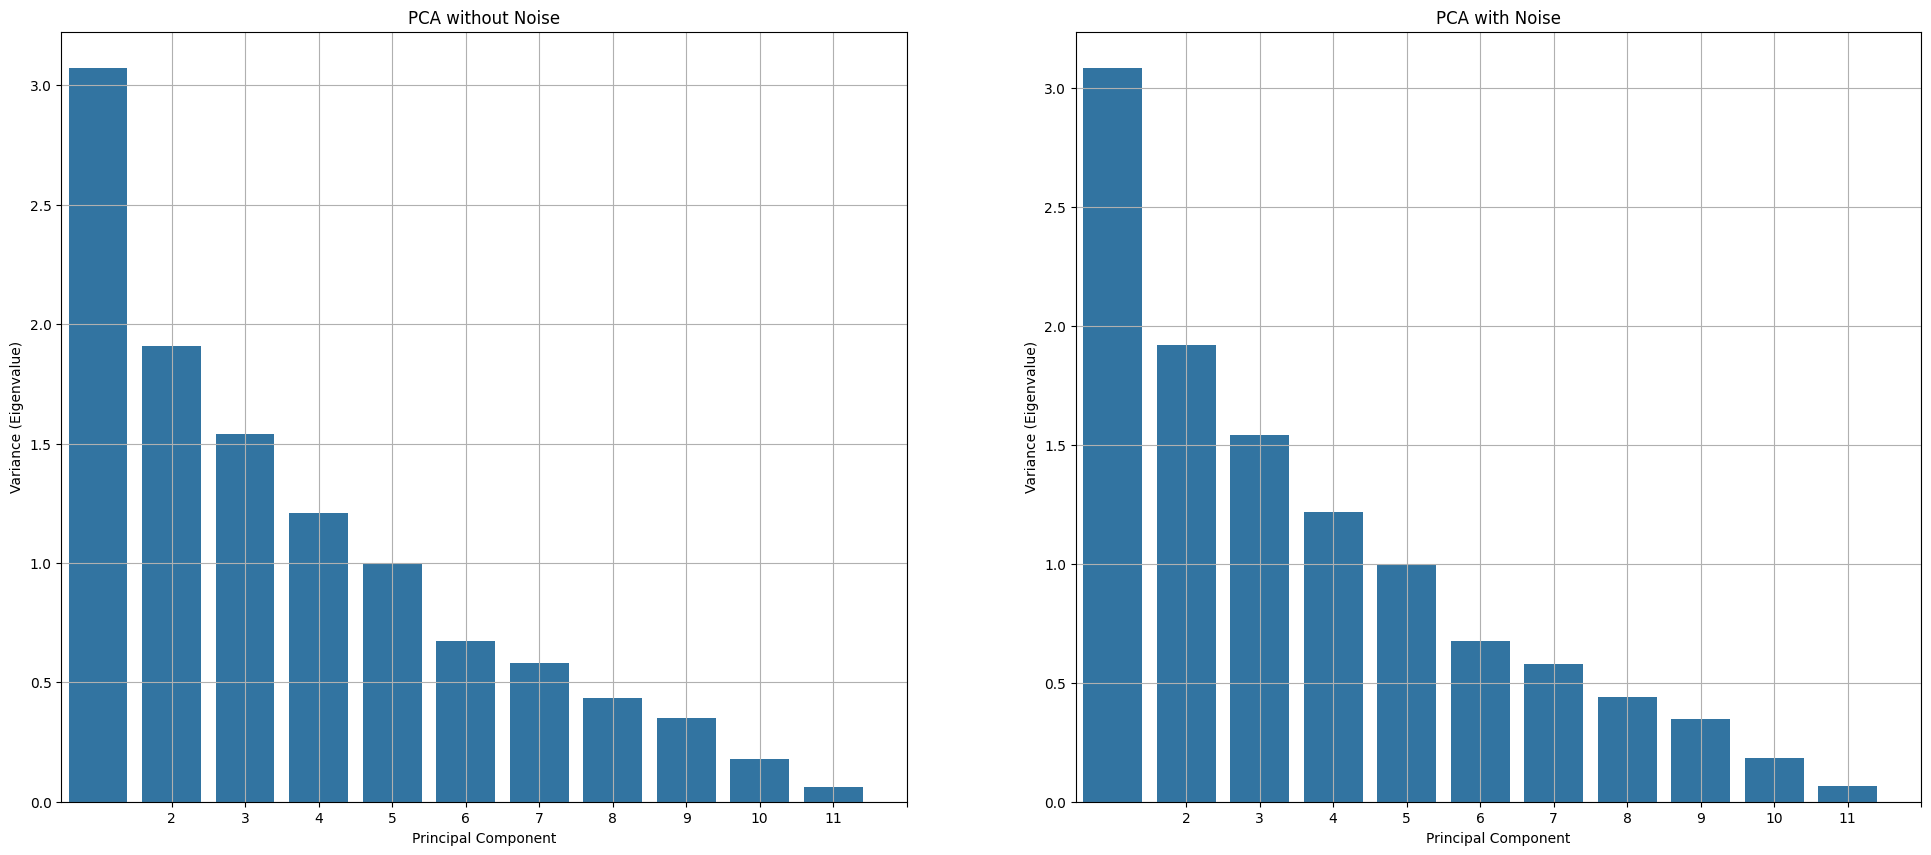

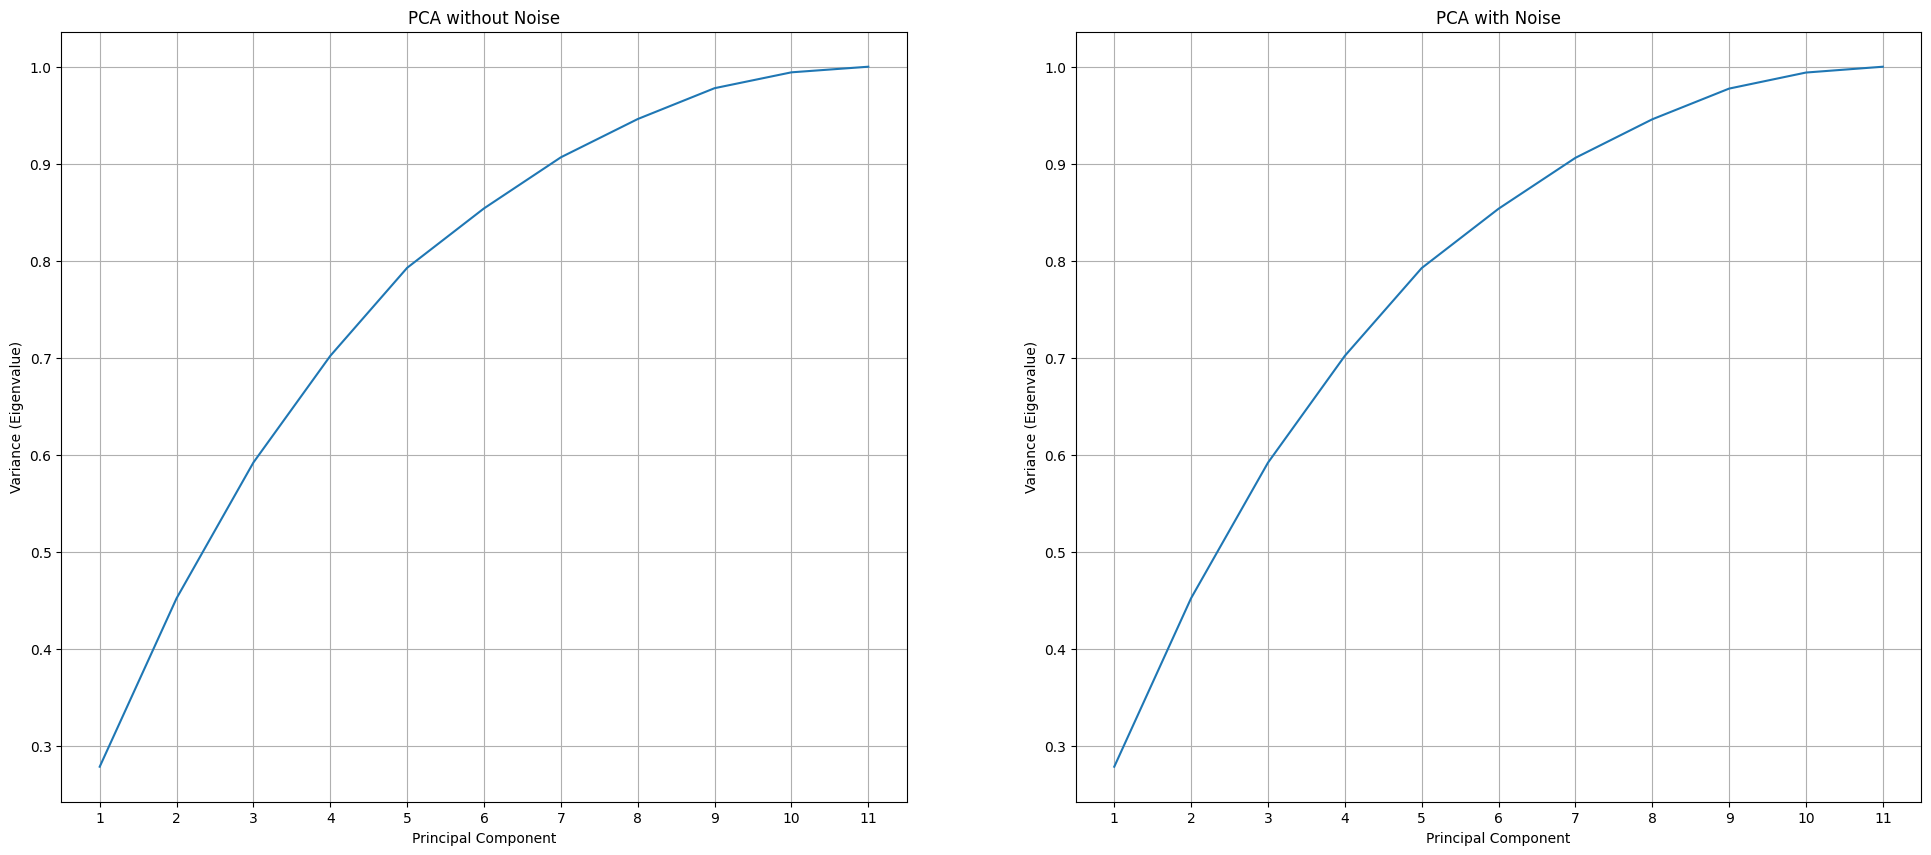

In [38]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt


pca_train = PCA(random_state=42)
pca_train.fit(X_train)
print(f"Variance without noise: {pca_train.explained_variance_}")

pca_train_noisy = PCA(random_state=42)
pca_train_noisy.fit(X_train_noisy)
print(f"Variance with noise: {pca_train_noisy.explained_variance_}")


def plot_pca(explained_variances: list, titles: list, plot_mode: str = "bar"):
    _, ax = plt.subplots(1, len(explained_variances), figsize=(24, 10))
    for i, (explained_variance, t) in enumerate(zip(explained_variances, titles)):
        plot = plot_mode == "bar" and sns.barplot or sns.lineplot
        plot(x=range(1, len(explained_variance) + 1), y=explained_variance, ax=ax[i])
        ax[i].set_title(t)
        ax[i].set_xlabel("Principal Component")
        ax[i].set_ylabel("Variance (Eigenvalue)")
        ax[i].set_xticks(range(1, len(explained_variance) + 1))
        ax[i].grid()
    plt.show()


names = ["PCA without Noise", "PCA with Noise"]
plot_pca(
    [pca_train.explained_variance_, pca_train_noisy.explained_variance_],
    names,
    plot_mode="bar",
)
plot_pca(
    [np.cumsum(pca_train.explained_variance_ratio_), np.cumsum(pca_train_noisy.explained_variance_ratio_)],
    names,
    plot_mode="line",
)

### Reconstruction using principal components

Plotting decision trees with PCA reconstructed data...
Best Depth: 5
Most Overfit Depth: 11


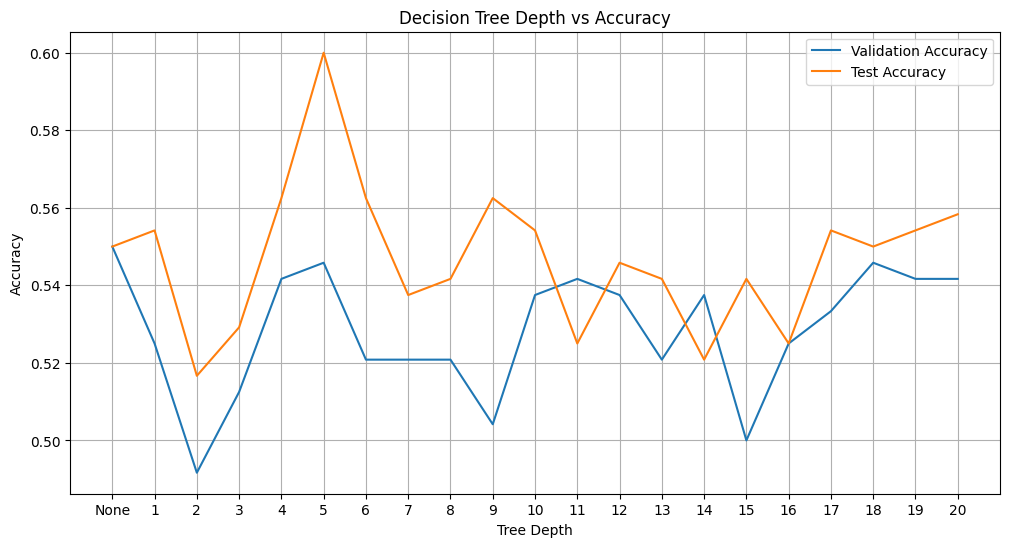



In [39]:
from sklearn.decomposition import PCA
import numpy as np


def reconstruct_pca(pca: PCA, X: np.ndarray, variance_threshold: float = 0.95) -> np.ndarray:
    # Determine number of components to reach the variance threshold
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
    n_components = np.searchsorted(cumulative_variance, variance_threshold) + 1

    # Project data to lower-dimensional space and back to original space
    X_reduced = pca.transform(X)[:, :n_components]
    X_reconstructed = np.dot(X_reduced, pca.components_[:n_components, :]) + pca.mean_

    return X_reconstructed


X_train_reconstructed = reconstruct_pca(pca_train_noisy, X_train)
print("Plotting decision trees with PCA reconstructed data...")
plot_trees(X_train_reconstructed, y_train, X_val, y_val, X_test, y_test)

### Visualize data used in decision trees

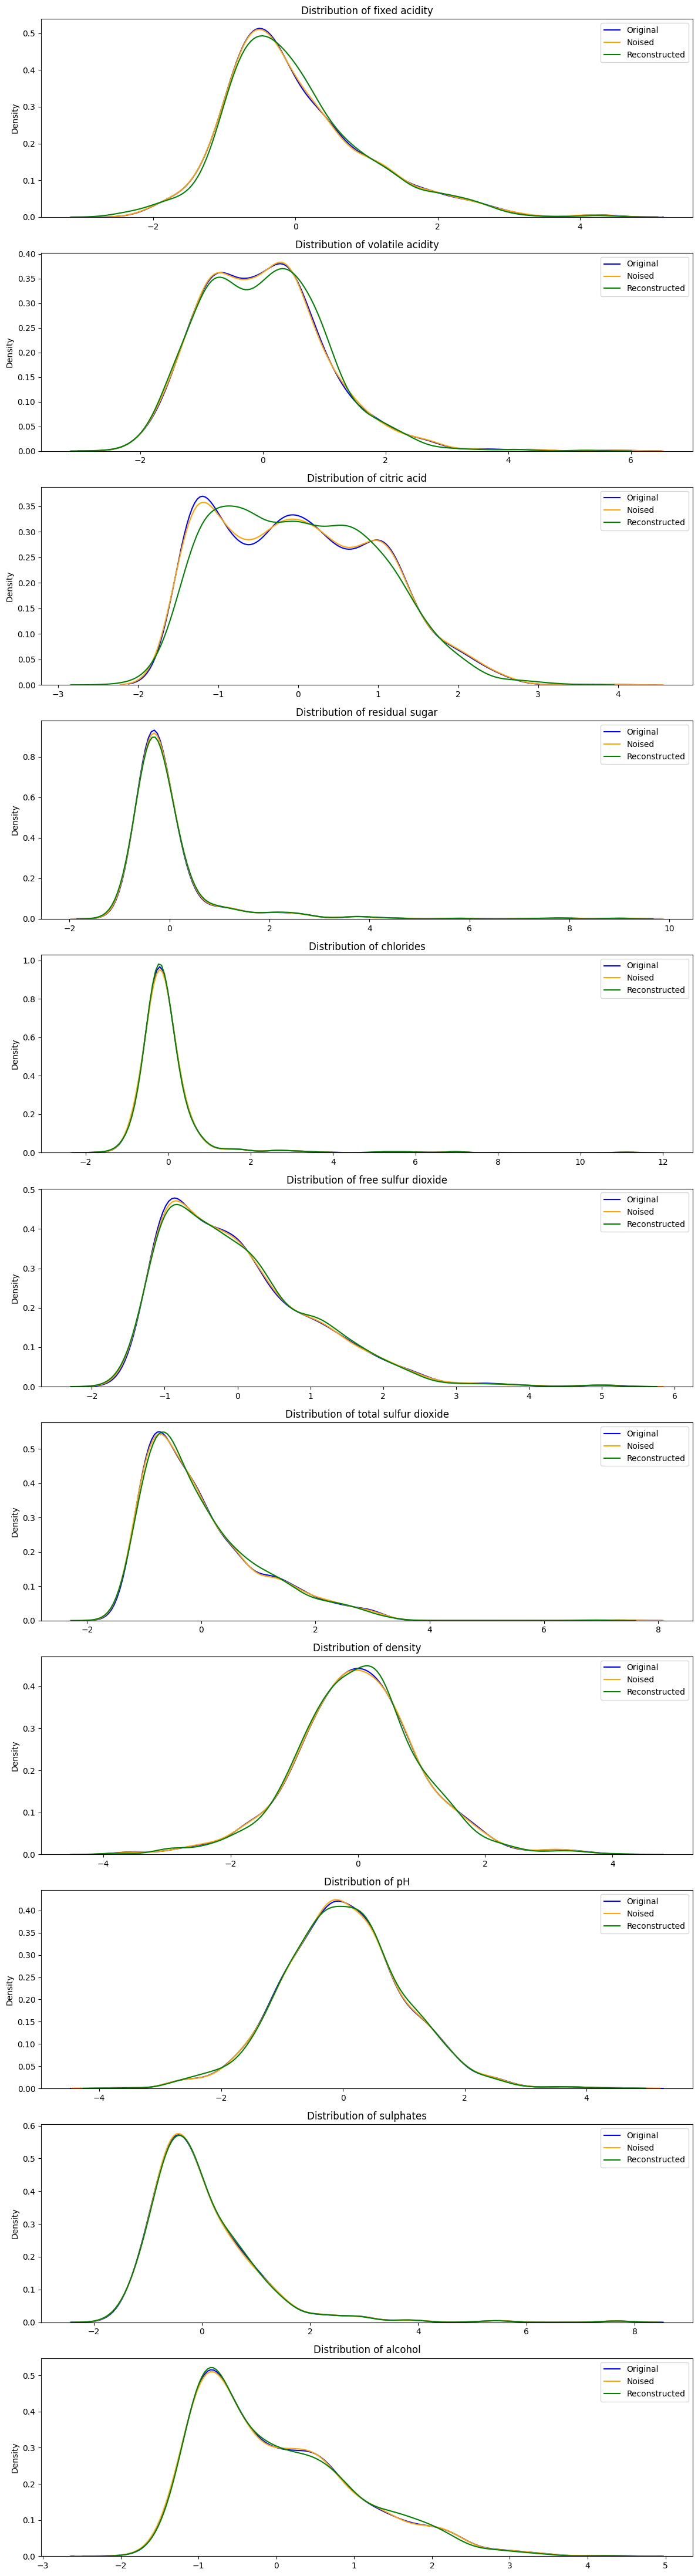

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt


def plot_feature_distributions(original: np.ndarray, noised: np.ndarray, reconstructed: np.ndarray, feature_names: list[str]):
    """Visualize original, noised and reconstructed data distributions"""
    num_features = original.shape[1]
    _, axes = plt.subplots(num_features, 1, figsize=(12, 4 * num_features))
    
    for i in range(num_features):
        sns.kdeplot(original[:, i], ax=axes[i], label='Original', color='blue')
        sns.kdeplot(noised[:, i], ax=axes[i], label='Noised', color='orange')
        sns.kdeplot(reconstructed[:, i], ax=axes[i], label='Reconstructed', color='green')
        axes[i].set_title(f'Distribution of {feature_names[i]}')
        axes[i].legend()
    
    plt.tight_layout()
    plt.show()


feature_names = df.drop(columns=[target_col]).columns.to_list()
plot_feature_distributions(X_train, X_train_noisy, X_train_reconstructed, feature_names)